# Loading data

In [32]:
import pandas as pd
from pathlib import Path
import statsmodels.api as sm
import matplotlib.pyplot as plt

project_root = Path("..")

# Notebook is located under 10_code
project_root = Path("..")

# Left file 2000-2010
input_path = project_root / "00_data" / "processed" / "master_county_year_panel.csv"

# load the data
df = pd.read_csv(input_path)

df

,state,county,year,population,total_pills,total_mme,n_transactions,drug_deaths,missing_deaths,mme_per_capita,...,log_overdoses_per_100k,is_FL,is_WA,group_FL,group_WA,treated,post,t_minus_policy,county_fe,year_fe
0,AL,AUTAUGA,2006,51328,2.850573e+06,5.166274e+07,8838.0,NaN,1,1006.521665,...,NaN,0,0,control_FL,other,0,0,NaN,AL_AUTAUGA,2006
1,AL,BALDWIN,2006,168121,8.586086e+06,1.628179e+08,30450.0,11.0,0,968.456784,...,2.020608,0,0,control_FL,other,0,0,NaN,AL_BALDWIN,2006
2,AL,BARBOUR,2006,27861,1.018382e+06,1.169558e+07,4356.0,NaN,1,419.783224,...,NaN,0,0,control_FL,other,0,0,NaN,AL_BARBOUR,2006
3,AL,BIBB,2006,22099,9.624879e+05,1.658575e+07,3270.0,NaN,1,750.520260,...,NaN,0,0,control_FL,other,0,0,NaN,AL_BIBB,2006
4,AL,BLOUNT,2006,55485,1.590574e+06,2.555605e+07,4541.0,NaN,1,460.593891,...,NaN,0,0,control_FL,other,0,0,NaN,AL_BLOUNT,2006
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5215,WA,WAHKIAKUM,2015,4035,1.322830e+05,1.670586e+06,553.0,NaN,1,414.023840,...,NaN,0,1,other,treated_WA,1,1,3.0,WA_WAHKIAKUM,2015
5216,WA,WALLA WALLA,2015,59726,5.353771e+06,8.184576e+07,14808.0,NaN,1,1370.354030,...,NaN,0,1,other,treated_WA,1,1,3.0,WA_WALLA WALLA,2015
5217,WA,WHATCOM,2015,207100,9.873313e+06,2.436225e+08,33041.0,23.0,0,1176.352199,...,2.493680,0,1,other,treated_WA,1,1,3.0,WA_WHATCOM,2015
5218,WA,WHITMAN,2015,46737,1.692291e+06,2.508456e+07,6608.0,NaN,1,536.717393,...,NaN,0,1,other,treated_WA,1,1,3.0,WA_WHITMAN,2015


###############################################################################################################

# Mortality Part

## 1. Define plot functions (replace NaN value + plot)

In [33]:
import matplotlib.pyplot as plt
import statsmodels.api as sm


def plot_pre_post_with_ci(
    df,
    state_code,
    policy_year,
    rate_col="overdoses_per_100k",
    pre_window=4,
    post_window=4,
    state_label=None,
    nan_strategy="drop",
):
    """
    Pre-Post plot with linear trends and 95% CI.

    NaN handling strategies (applied BEFORE aggregation to state-year):
      - 'drop'        : don't fill; rows with NaN will be dropped after aggregation
      - 'mean'        : fill NaN with overall mean (within this state)
      - 'median'      : fill NaN with overall median (within this state)
      - 'ffill'       : forward-fill within each county ordered by year
      - 'bfill'       : backward-fill within each county ordered by year
      - 'interpolate' : linear interpolation within each county ordered by year
    """

    if state_label is None:
        state_label = state_code

    # 1. keep only the selected state
    df_state = df[df["state"] == state_code].copy()

    # detect whether we have county-level data
    county_col = "county" if "county" in df_state.columns else None

    # -----------------------------------------
    # 2. NaN Handling BEFORE aggregation
    # -----------------------------------------
    if nan_strategy == "mean":
        df_state[rate_col] = df_state[rate_col].fillna(df_state[rate_col].mean())

    elif nan_strategy == "median":
        df_state[rate_col] = df_state[rate_col].fillna(df_state[rate_col].median())

    elif nan_strategy == "ffill":
        if county_col is not None:
            # sort within county by year, then forward-fill per county
            df_state = df_state.sort_values([county_col, "year"])
            df_state[rate_col] = df_state.groupby(county_col)[rate_col].ffill()
        else:
            df_state = df_state.sort_values("year")
            df_state[rate_col] = df_state[rate_col].ffill()

    elif nan_strategy == "bfill":
        if county_col is not None:
            df_state = df_state.sort_values([county_col, "year"])
            df_state[rate_col] = df_state.groupby(county_col)[rate_col].bfill()
        else:
            df_state = df_state.sort_values("year")
            df_state[rate_col] = df_state[rate_col].bfill()

    elif nan_strategy == "interpolate":
        if county_col is not None:
            df_state = df_state.sort_values([county_col, "year"])
            df_state[rate_col] = (
                df_state.groupby(county_col)[rate_col]
                .apply(lambda s: s.interpolate(method="linear"))
                .reset_index(level=0, drop=True)
            )
        else:
            df_state = df_state.sort_values("year")
            df_state[rate_col] = df_state[rate_col].interpolate(method="linear")

    elif nan_strategy == "drop":
        # do nothing here; rows with NaN will be dropped after aggregation
        pass

    else:
        raise ValueError("Invalid nan_strategy choice.")

    # 3. aggregate to state-year (mean county rate within state-year)
    state_year = (
        df_state.groupby("year", as_index=False)[rate_col]
        .mean()
        .rename(columns={rate_col: "rate"})
    )

    # after aggregation, drop remaining NAs (if any)
    state_year = state_year.dropna(subset=["rate"])

    # 4. split into pre/post periods
    pre_mask = (state_year["year"] >= policy_year - pre_window) & (
        state_year["year"] < policy_year
    )
    post_mask = (state_year["year"] >= policy_year) & (
        state_year["year"] <= policy_year + post_window
    )

    pre = state_year[pre_mask].copy()
    post = state_year[post_mask].copy()

    if pre.empty or post.empty:
        print(f"Not enough data for {state_label} around {policy_year}.")
        return

    # helper: linear regression + CI
    def fit_trend(seg):
        seg = seg.dropna(subset=["rate"])
        X = sm.add_constant(seg["year"])
        model = sm.OLS(seg["rate"], X).fit()
        pred = model.get_prediction(X)
        mean = pred.predicted_mean
        ci = pred.conf_int()
        return mean, ci[:, 0], ci[:, 1]

    pre_pred, pre_low, pre_high = fit_trend(pre)
    post_pred, post_low, post_high = fit_trend(post)

    # 5. plot
    plt.figure(figsize=(10, 4))

    x_pre = pre["year"].to_numpy()
    x_post = post["year"].to_numpy()

    plt.plot(x_pre, pre_pred, color="blue", label=f"Pre-Policy ({nan_strategy})")
    plt.fill_between(x_pre, pre_low, pre_high, alpha=0.15, color="blue")

    plt.plot(x_post, post_pred, color="red", label="Post-Policy")
    plt.fill_between(x_post, post_low, post_high, alpha=0.15, color="red")

    plt.axvline(policy_year, color="orange", linestyle="--")

    plt.title(
        f"Pre-Post Policy Analysis for {state_label} ({nan_strategy} NaN handling)"
    )
    plt.xlabel("Year")
    plt.ylabel(rate_col)
    plt.legend()
    plt.tight_layout()
    plt.show()

## 2. Compare different NaN value dealing ways (bigger plots)

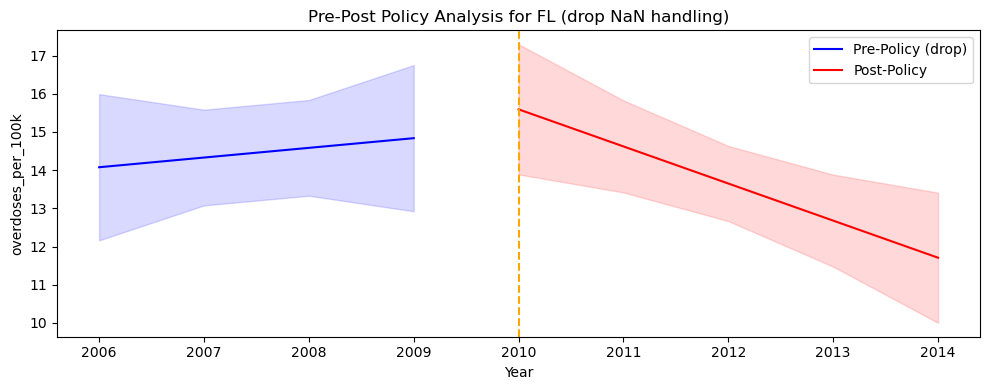

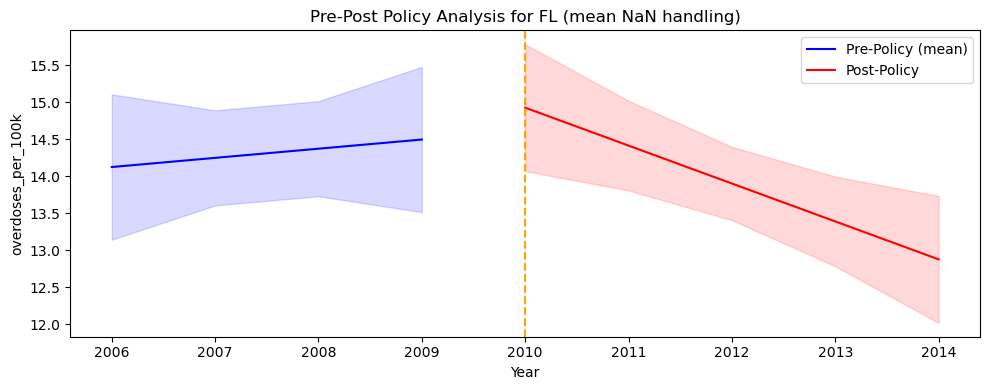

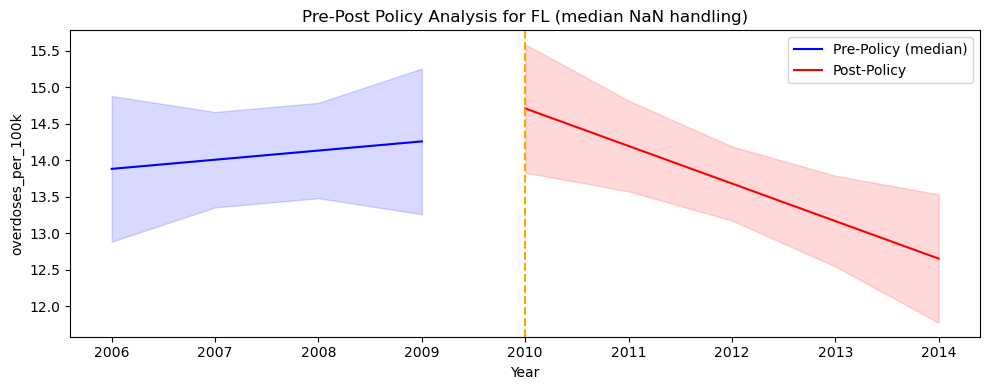

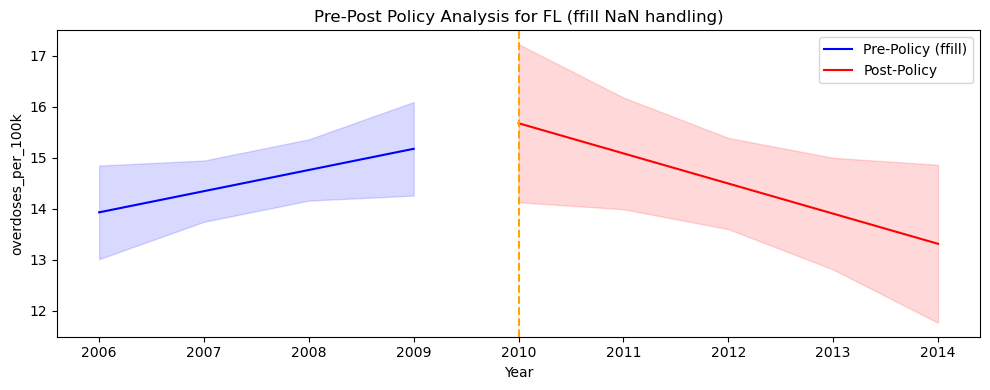

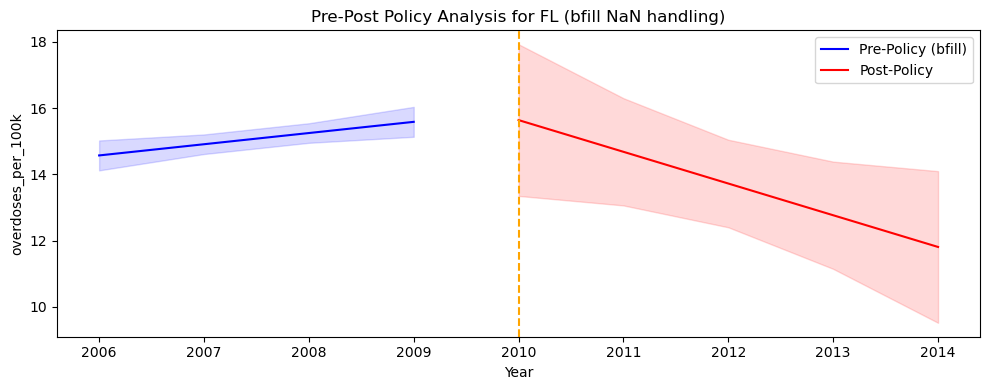

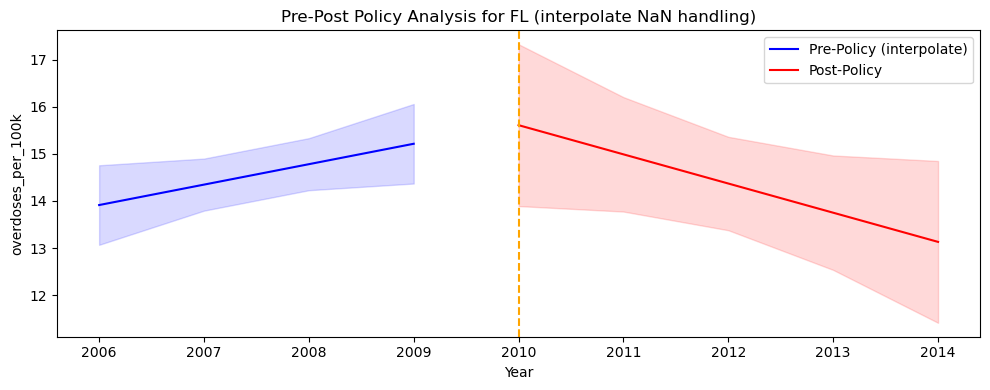

In [34]:
# Florida
# 1. drop
plot_pre_post_with_ci(
    df, "FL", 2010, rate_col="overdoses_per_100k", nan_strategy="drop"
)

# 2. mean
plot_pre_post_with_ci(
    df, "FL", 2010, rate_col="overdoses_per_100k", nan_strategy="mean"
)

# 3. median
plot_pre_post_with_ci(
    df, "FL", 2010, rate_col="overdoses_per_100k", nan_strategy="median"
)

# 4. ffill
plot_pre_post_with_ci(
    df, "FL", 2010, rate_col="overdoses_per_100k", nan_strategy="ffill"
)

# 5. bfill
plot_pre_post_with_ci(
    df, "FL", 2010, rate_col="overdoses_per_100k", nan_strategy="bfill"
)

# 6. interpolate
plot_pre_post_with_ci(
    df, "FL", 2010, rate_col="overdoses_per_100k", nan_strategy="interpolate"
)

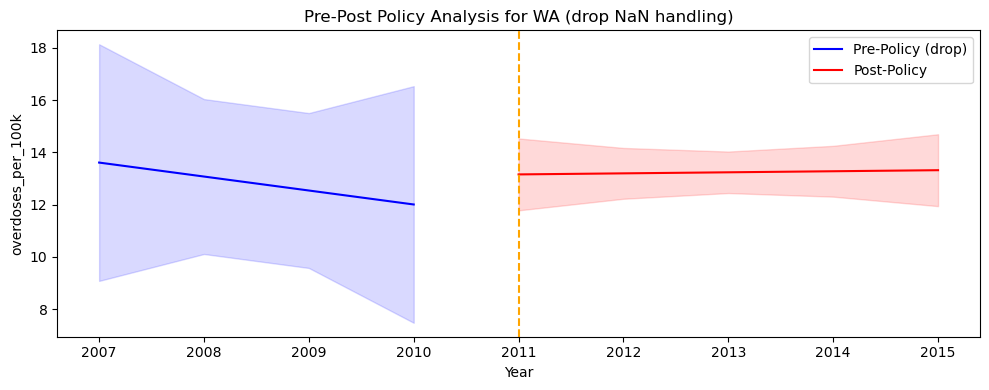

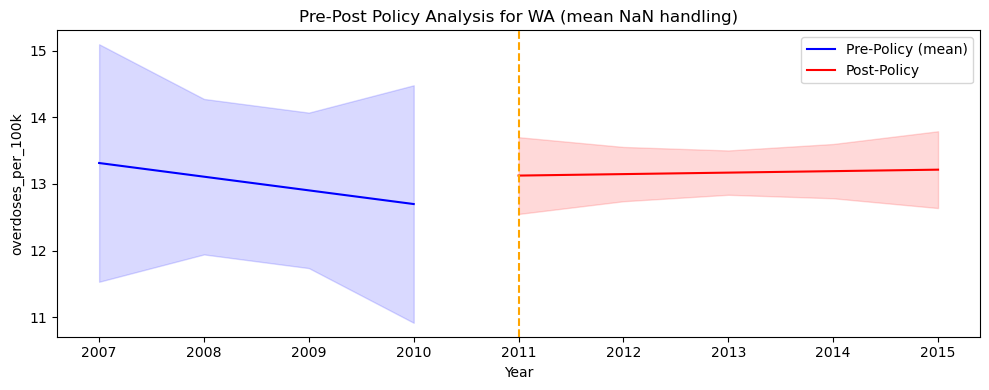

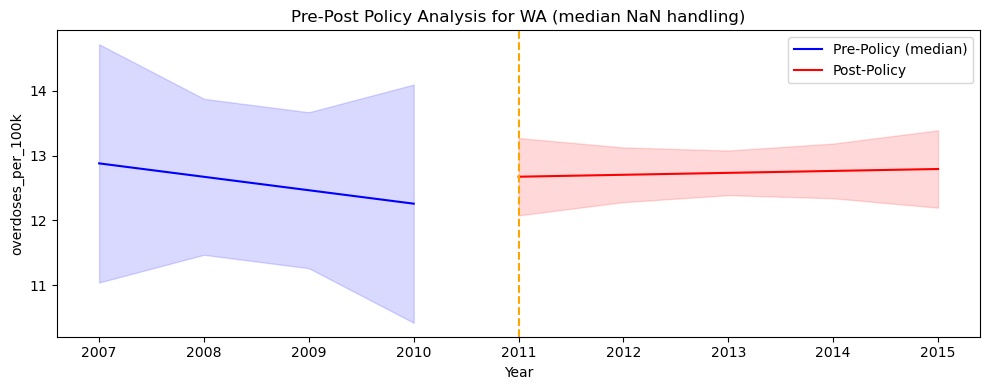

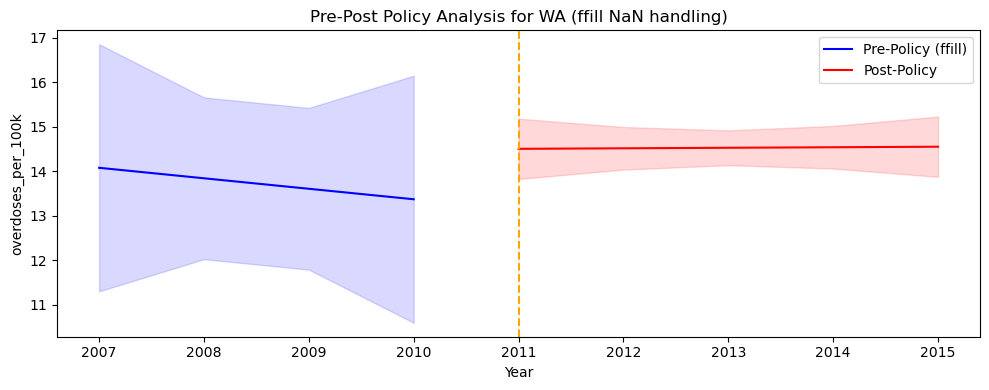

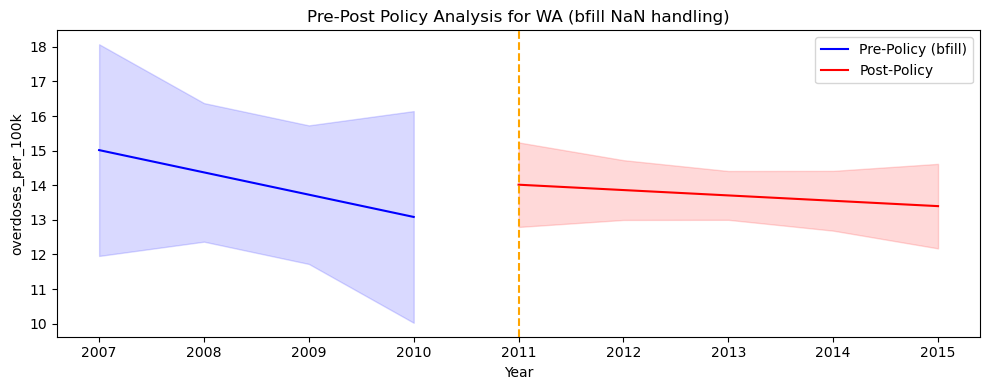

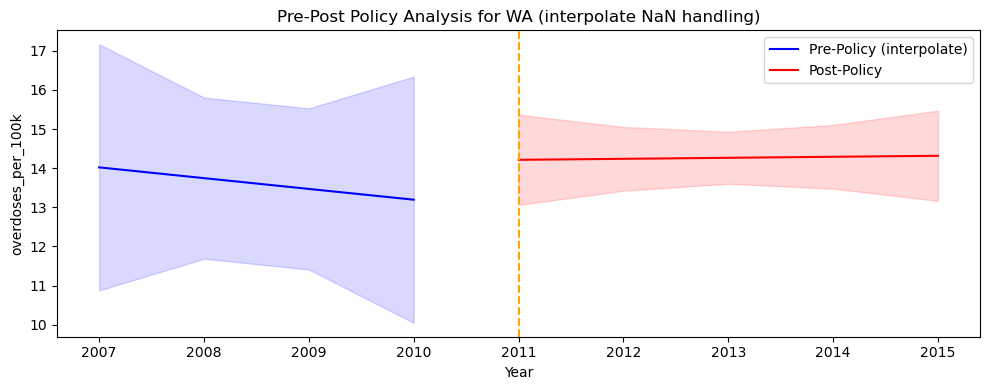

In [35]:
# Washington
# 1. drop
plot_pre_post_with_ci(
    df, "WA", 2011, rate_col="overdoses_per_100k", nan_strategy="drop"
)

# 2. mean
plot_pre_post_with_ci(
    df, "WA", 2011, rate_col="overdoses_per_100k", nan_strategy="mean"
)

# 3. median
plot_pre_post_with_ci(
    df, "WA", 2011, rate_col="overdoses_per_100k", nan_strategy="median"
)

# 4. ffill
plot_pre_post_with_ci(
    df, "WA", 2011, rate_col="overdoses_per_100k", nan_strategy="ffill"
)

# 5. bfill
plot_pre_post_with_ci(
    df, "WA", 2011, rate_col="overdoses_per_100k", nan_strategy="bfill"
)

# 6. interpolate
plot_pre_post_with_ci(
    df, "WA", 2011, rate_col="overdoses_per_100k", nan_strategy="interpolate"
)

## 3. Compare different NaN value dealing ways (smaller plots)

In [36]:
import matplotlib.pyplot as plt
import statsmodels.api as sm


def plot_pre_post_grid(
    df,
    state_code,
    policy_year,
    rate_col="overdoses_per_100k",
    pre_window=4,
    post_window=4,
):
    """
    Draw 6 pre/post plots (one for each NaN strategy) for a single state.
    NaN handling rules are consistent with all other functions:

      - "drop":        leave NaN unchanged (dropped after aggregation)
      - "mean":        fill NaN using state-level mean
      - "median":      fill NaN using state-level median
      - "ffill":       forward-fill within each time series
                       (state+county if county exists, else state only)
      - "bfill":       backward-fill within each time series
                       (state+county if county exists, else state only)
      - "interpolate": linear interpolation within each time series
                       (state+county if county exists, else state only)
    """

    strategies = ["drop", "mean", "median", "ffill", "bfill", "interpolate"]

    df = df.copy()
    df["state"] = df["state"].str.upper()
    state_code = state_code.upper()

    df_state = df[df["state"] == state_code].copy()

    if df_state.empty:
        print(f"No data found for state {state_code}.")
        return

    # Detect county column for panel-style filling
    county_col = "county" if "county" in df_state.columns else None

    fig, axes = plt.subplots(3, 2, figsize=(14, 12))
    axes = axes.flatten()

    # Fixed y-scale across subplots
    all_values = df_state[rate_col].dropna()
    y_min, y_max = all_values.min(), all_values.max()

    for i, strat in enumerate(strategies):
        ax = axes[i]
        panel = df_state.copy()

        # --------------------------------------
        # NaN handling (consistent logic)
        # --------------------------------------
        if strat != "drop":

            # Mean / median: state-level
            if strat in ["mean", "median"]:
                state_g = panel.groupby("state")[rate_col]
                if strat == "mean":
                    panel[rate_col] = state_g.transform(lambda s: s.fillna(s.mean()))
                else:
                    panel[rate_col] = state_g.transform(lambda s: s.fillna(s.median()))

            else:
                # Time-series filling: ffill, bfill, interpolate
                if county_col:
                    # Fill within state + county
                    panel = panel.sort_values(["state", county_col, "year"])
                    group_cols = ["state", county_col]
                else:
                    # Fill within state only
                    panel = panel.sort_values(["state", "year"])
                    group_cols = ["state"]

                g = panel.groupby(group_cols)[rate_col]

                if strat == "ffill":
                    panel[rate_col] = g.transform(lambda s: s.ffill())
                elif strat == "bfill":
                    panel[rate_col] = g.transform(lambda s: s.bfill())
                elif strat == "interpolate":
                    panel[rate_col] = g.transform(
                        lambda s: s.interpolate(method="linear")
                    )

        # --------------------------------------
        # Aggregate to state-year
        # --------------------------------------
        state_year = (
            panel.groupby("year", as_index=False)[rate_col]
            .mean()
            .rename(columns={rate_col: "rate"})
            .dropna(subset=["rate"])
        )

        if state_year.empty:
            ax.set_title(f"{strat} (no usable data)")
            ax.axis("off")
            continue

        # --------------------------------------
        # Pre / Post windows
        # --------------------------------------
        pre = state_year[
            (state_year["year"] >= policy_year - pre_window)
            & (state_year["year"] < policy_year)
        ]

        post = state_year[
            (state_year["year"] >= policy_year)
            & (state_year["year"] <= policy_year + post_window)
        ]

        if pre.empty or post.empty:
            ax.set_title(f"{strat} (insufficient data)")
            ax.axis("off")
            continue

        # --------------------------------------
        # Fit linear trend + CI
        # --------------------------------------
        def fit_segment(seg):
            X = sm.add_constant(seg["year"])
            model = sm.OLS(seg["rate"], X).fit()
            preds = model.get_prediction(X)
            mean = preds.predicted_mean
            ci = preds.conf_int()
            return mean, ci[:, 0], ci[:, 1]

        pre_mean, pre_low, pre_high = fit_segment(pre)
        post_mean, post_low, post_high = fit_segment(post)

        # --------------------------------------
        # Plot
        # --------------------------------------
        ax.plot(pre["year"], pre_mean, color="blue", label="Pre")
        ax.fill_between(pre["year"], pre_low, pre_high, color="blue", alpha=0.15)

        ax.plot(post["year"], post_mean, color="red", label="Post")
        ax.fill_between(post["year"], post_low, post_high, color="red", alpha=0.15)

        ax.axvline(policy_year, color="black", linestyle="--")

        ax.set_title(f"{strat}", fontsize=12)
        ax.set_ylim(y_min, y_max)
        ax.set_xlabel("Year")
        ax.set_ylabel(rate_col)

    fig.suptitle(f"{state_code}: Pre-Post Comparison (6 NaN Strategies)", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

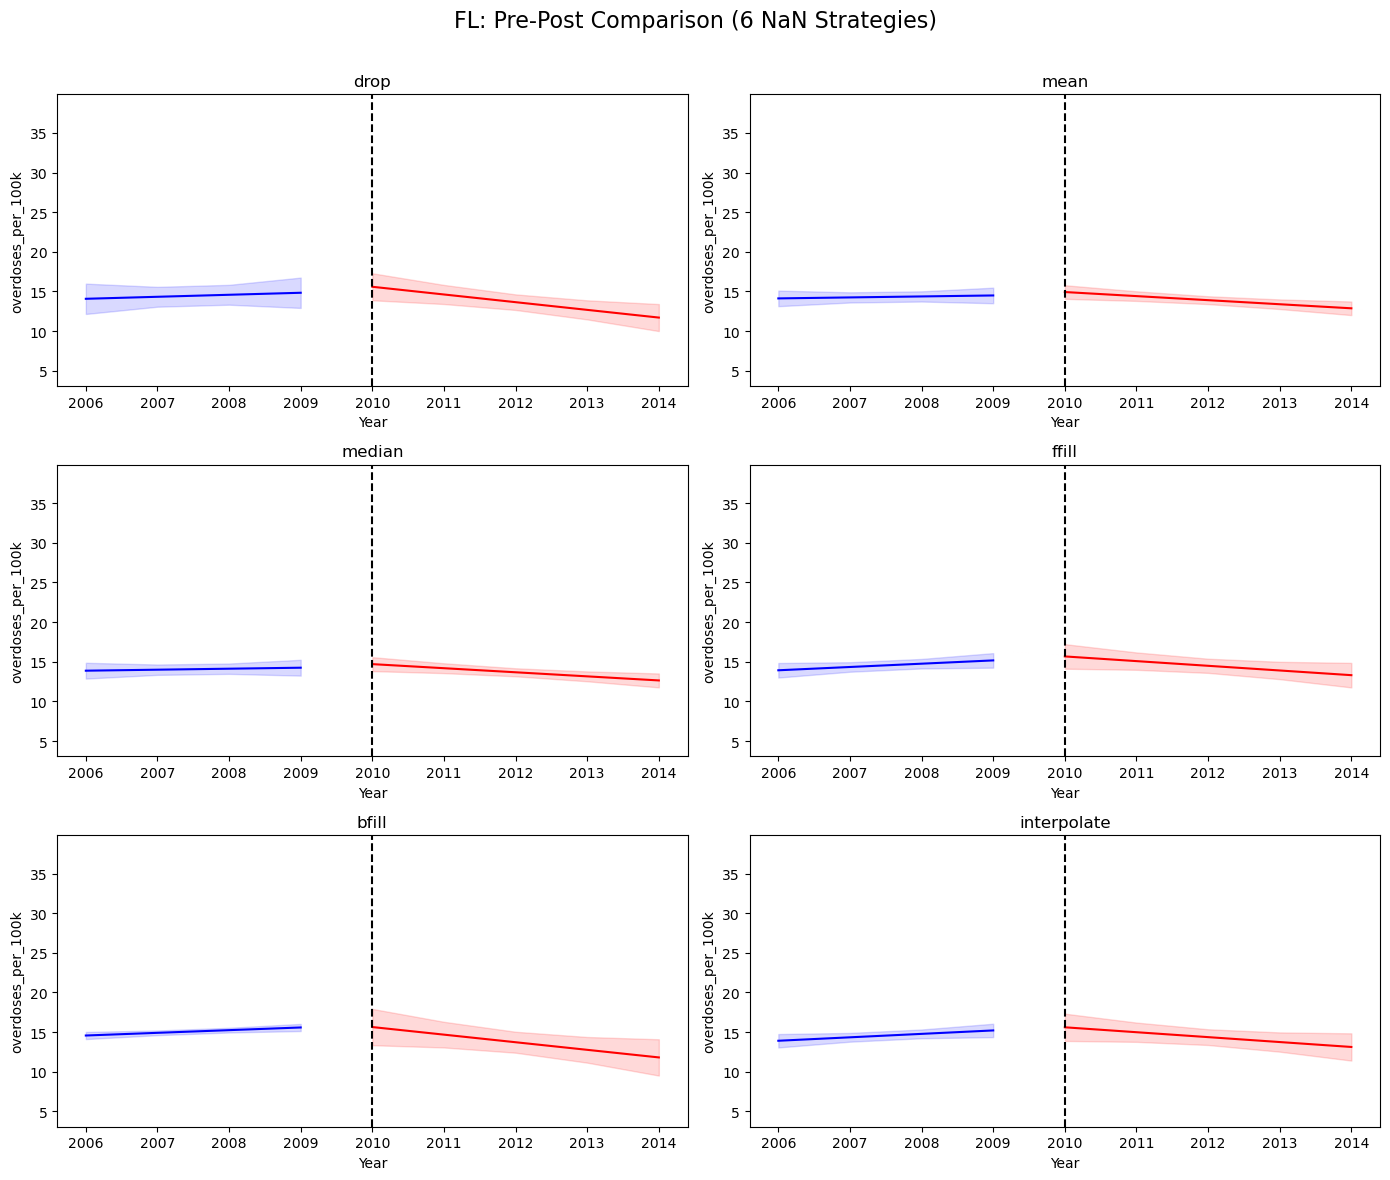

In [37]:
# Florida
plot_pre_post_grid(df, "FL", 2010, rate_col="overdoses_per_100k")

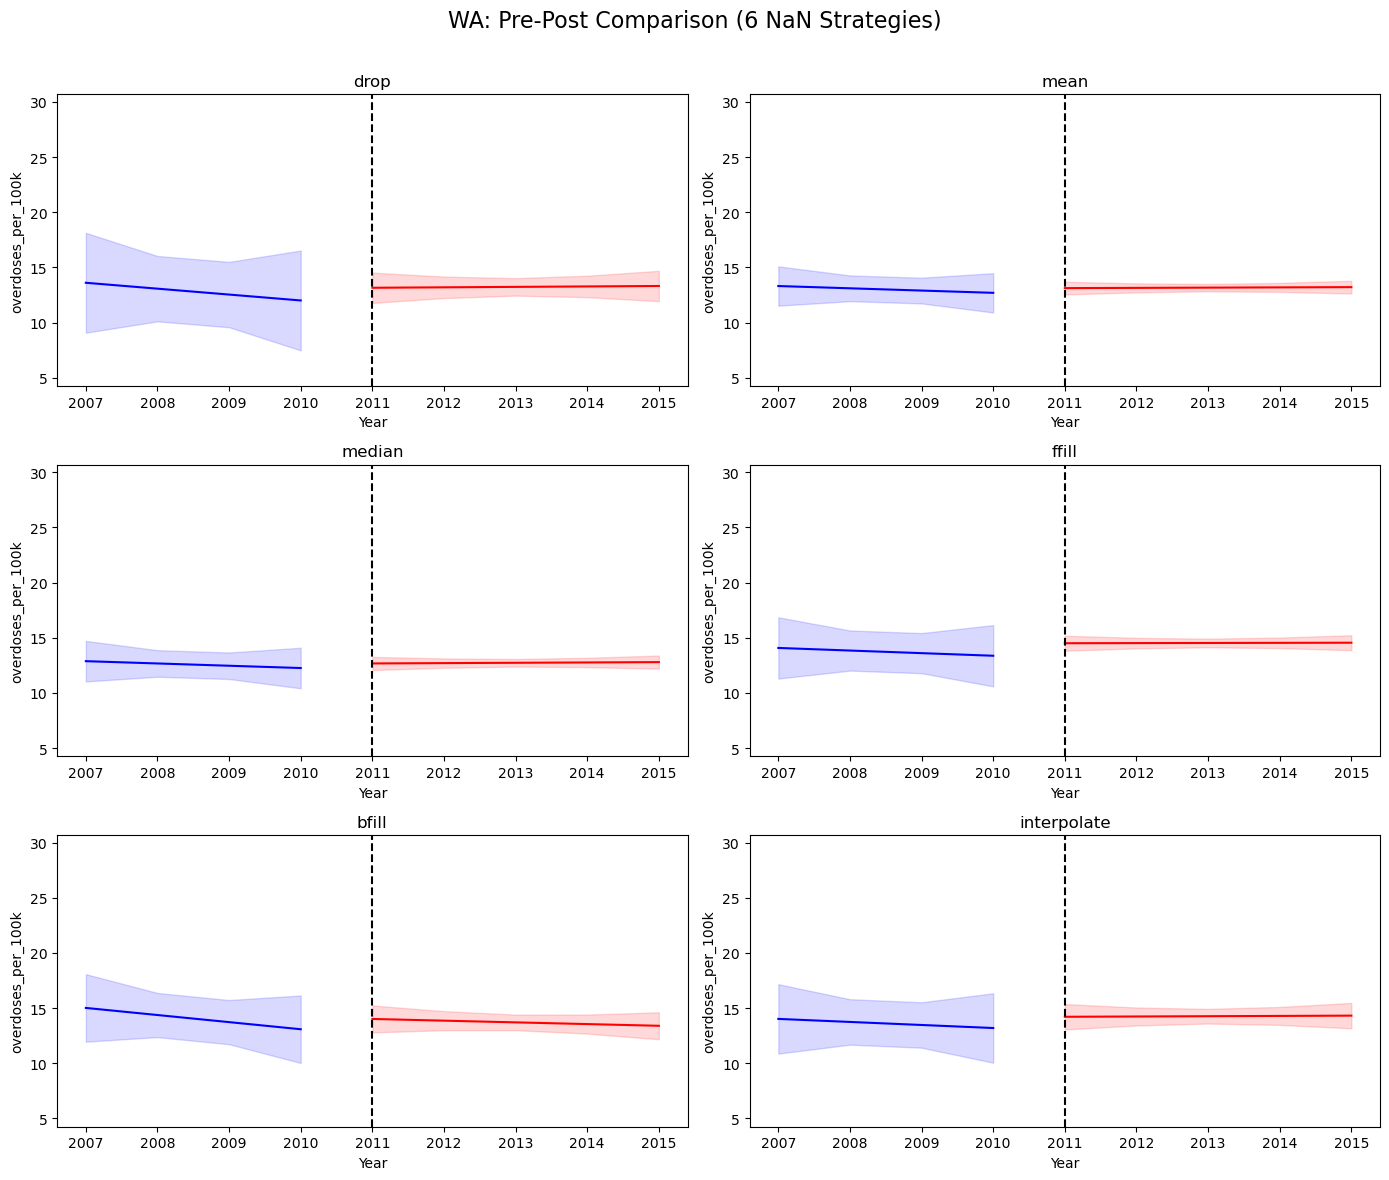

In [38]:
# Washington
plot_pre_post_grid(df, "WA", 2011, rate_col="overdoses_per_100k")

## 4. Final Result (for Mortality) (Pending now)

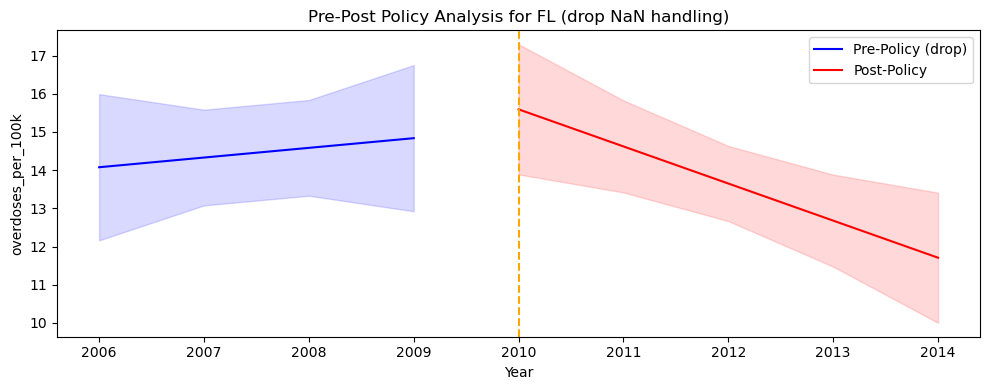

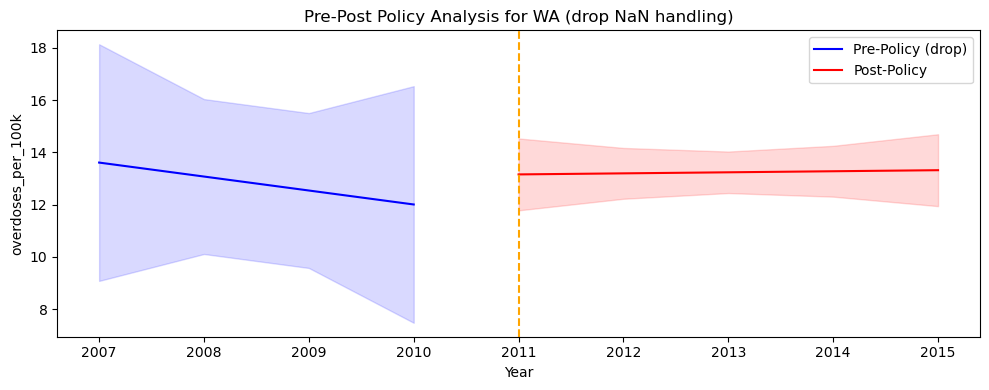

In [39]:
# Florida: policy year 2010, use 2006–2009 vs 2010–2014
plot_pre_post_with_ci(
    df,
    state_code="FL",
    policy_year=2010,
    rate_col="overdoses_per_100k",
    pre_window=4,
    post_window=4,
    state_label="FL",
)

# Washington: policy year 2011, use 2007–2010 vs 2011–2015
plot_pre_post_with_ci(
    df,
    state_code="WA",
    policy_year=2011,
    rate_col="overdoses_per_100k",
    pre_window=4,
    post_window=4,
    state_label="WA",
)

###############################################################################################################

# Shipment part

## 1. Define plot functions (replace NaN value + plot)

In [40]:
import matplotlib.pyplot as plt
import statsmodels.api as sm


def plot_pre_post_shipment(
    df,
    state_code,
    policy_year,
    rate_col="mme_per_capita",
    pre_window=4,
    post_window=3,
    nan_strategy="drop",
):
    """
    Pre-Post plot for shipment (e.g., MME per capita) with linear trends and 95% CI.

    NaN strategies (applied on raw rows before aggregating to state-year):
      - "drop":        leave NaN as is (rows with NaN will be dropped after aggregation)
      - "mean":        fill NaN with the state-specific mean
      - "median":      fill NaN with the state-specific median
      - "ffill":       forward fill within each county (sorted by year)
      - "bfill":       backward fill within each county (sorted by year)
      - "interpolate": linear interpolation within each county (sorted by year)
    """

    # Keep rows for the selected state only
    data = df[df["state"] == state_code].copy()

    # Detect county column for panel data
    county_col = "county" if "county" in data.columns else None

    # ---------- NaN handling at raw-row level ----------
    if nan_strategy == "mean":
        # Fill NaN with the mean rate within this state
        data[rate_col] = data[rate_col].fillna(data[rate_col].mean())

    elif nan_strategy == "median":
        # Fill NaN with the median rate within this state
        data[rate_col] = data[rate_col].fillna(data[rate_col].median())

    elif nan_strategy == "ffill":
        # Forward fill within each county (or the whole state if no county column)
        if county_col is not None:
            data = data.sort_values([county_col, "year"])
            data[rate_col] = data.groupby(county_col)[rate_col].ffill()
        else:
            data = data.sort_values("year")
            data[rate_col] = data[rate_col].ffill()

    elif nan_strategy == "bfill":
        # Backward fill within each county (or the whole state if no county column)
        if county_col is not None:
            data = data.sort_values([county_col, "year"])
            data[rate_col] = data.groupby(county_col)[rate_col].bfill()
        else:
            data = data.sort_values("year")
            data[rate_col] = data[rate_col].bfill()

    elif nan_strategy == "interpolate":
        # Linear interpolation within each county (or the whole state if no county column)
        if county_col is not None:
            data = data.sort_values([county_col, "year"])
            data[rate_col] = (
                data.groupby(county_col)[rate_col]
                .apply(lambda s: s.interpolate(method="linear"))
                .reset_index(level=0, drop=True)
            )
        else:
            data = data.sort_values("year")
            data[rate_col] = data[rate_col].interpolate(method="linear")

    elif nan_strategy == "drop":
        # Do nothing here; rows with NaN will be dropped after aggregation
        pass

    else:
        raise ValueError("Invalid nan_strategy choice.")

    # ---------- Aggregate to state-year ----------
    yearly = (
        data.groupby("year", as_index=False)[rate_col]
        .mean()
        .rename(columns={rate_col: "rate"})
        .dropna(subset=["rate"])  # drop years that still have missing rate
    )

    # ---------- Split into pre / post windows ----------
    pre = yearly[
        (yearly["year"] >= policy_year - pre_window) & (yearly["year"] < policy_year)
    ]
    post = yearly[
        (yearly["year"] >= policy_year) & (yearly["year"] <= policy_year + post_window)
    ]

    if pre.empty or post.empty:
        print(
            f"Not enough data for {state_code} around {policy_year} ({nan_strategy})."
        )
        return

    # ---------- Fit linear trends with confidence intervals ----------
    def fit_with_ci(seg):
        seg = seg.dropna(subset=["rate"])
        X = sm.add_constant(seg["year"])
        model = sm.OLS(seg["rate"], X).fit()
        pred = model.get_prediction(X)
        mean = pred.predicted_mean
        ci = pred.conf_int()
        return mean, ci[:, 0], ci[:, 1]

    pre_mean, pre_low, pre_high = fit_with_ci(pre)
    post_mean, post_low, post_high = fit_with_ci(post)

    # ---------- Plot ----------
    plt.figure(figsize=(10, 4))

    # Pre-policy (red)
    plt.plot(
        pre["year"],
        pre_mean,
        color="red",
        label=f"Pre-Policy ({policy_year-pre_window}–{policy_year-1})",
    )
    plt.fill_between(pre["year"], pre_low, pre_high, color="red", alpha=0.15)

    # Post-policy (blue)
    plt.plot(
        post["year"],
        post_mean,
        color="blue",
        label=f"Post-Policy ({policy_year}–{policy_year+post_window})",
    )
    plt.fill_between(post["year"], post_low, post_high, color="blue", alpha=0.15)

    # Policy implementation vertical line
    plt.axvline(policy_year, color="black", linestyle="--")

    # Labels and title
    plt.title(
        f"Pre-Post Analysis for shipment ({rate_col}) - {state_code} [{nan_strategy}]"
    )
    plt.ylabel(rate_col)
    plt.xlabel("Year")

    plt.legend()
    plt.tight_layout()
    plt.show()

## 2. Compare different NaN value dealing ways (bigger plots)

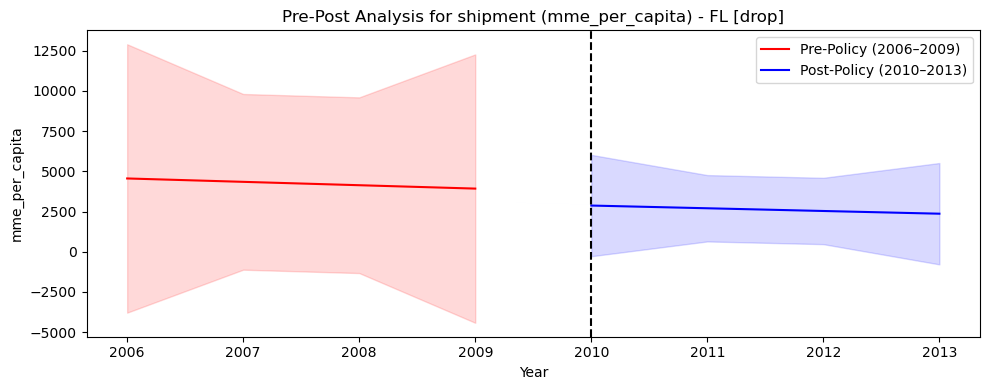

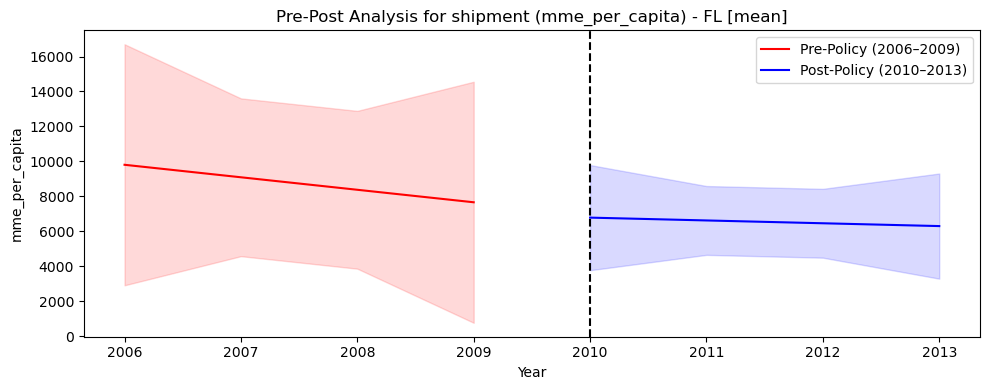

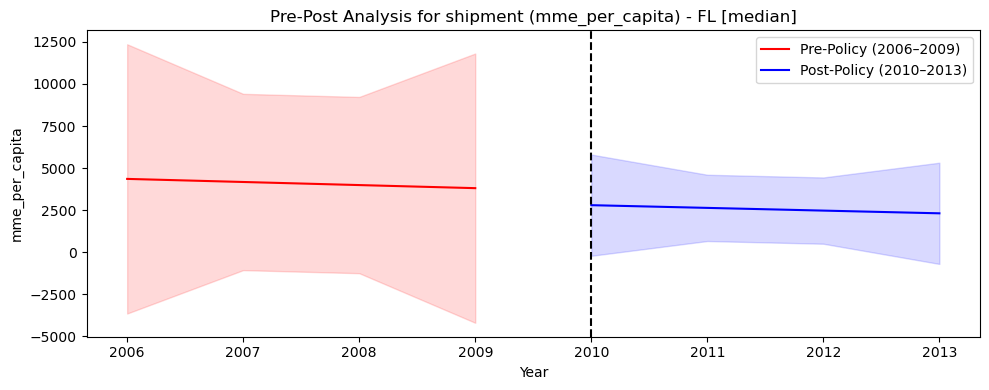

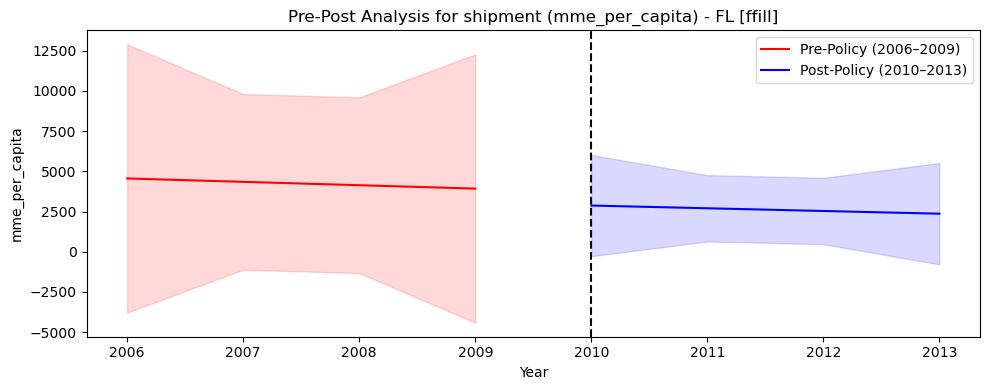

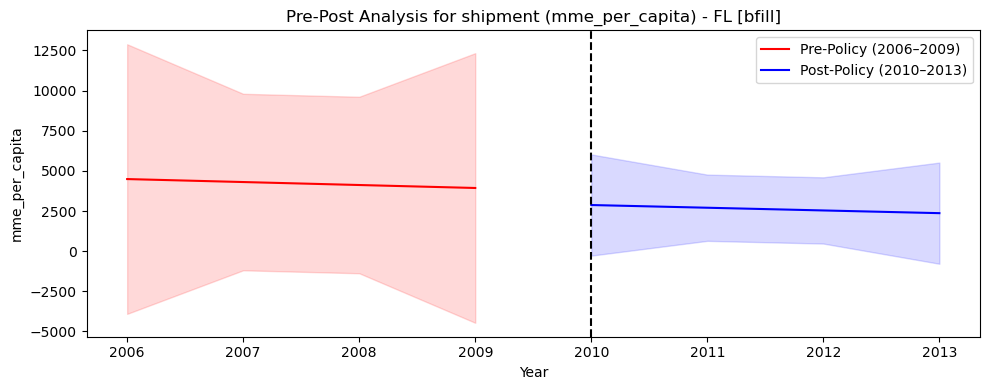

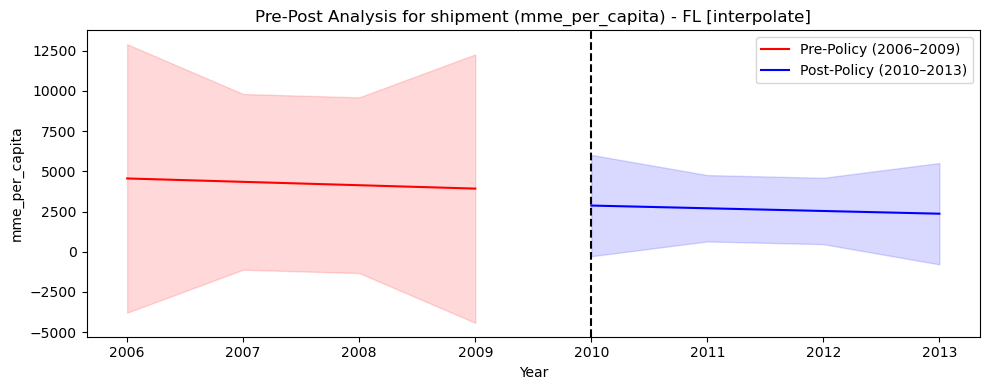

In [41]:
# Florida
# 1. drop
plot_pre_post_shipment(
    df,
    "FL",
    2010,
    rate_col="mme_per_capita",
    nan_strategy="drop",
)

# 2. mean
plot_pre_post_shipment(
    df,
    "FL",
    2010,
    rate_col="mme_per_capita",
    nan_strategy="mean",
)

# 3. median
plot_pre_post_shipment(
    df,
    "FL",
    2010,
    rate_col="mme_per_capita",
    nan_strategy="median",
)

# 4. ffill
plot_pre_post_shipment(
    df,
    "FL",
    2010,
    rate_col="mme_per_capita",
    nan_strategy="ffill",
)

# 5. bfill
plot_pre_post_shipment(
    df,
    "FL",
    2010,
    rate_col="mme_per_capita",
    nan_strategy="bfill",
)

# 6. interpolate
plot_pre_post_shipment(
    df,
    "FL",
    2010,
    rate_col="mme_per_capita",
    nan_strategy="interpolate",
)

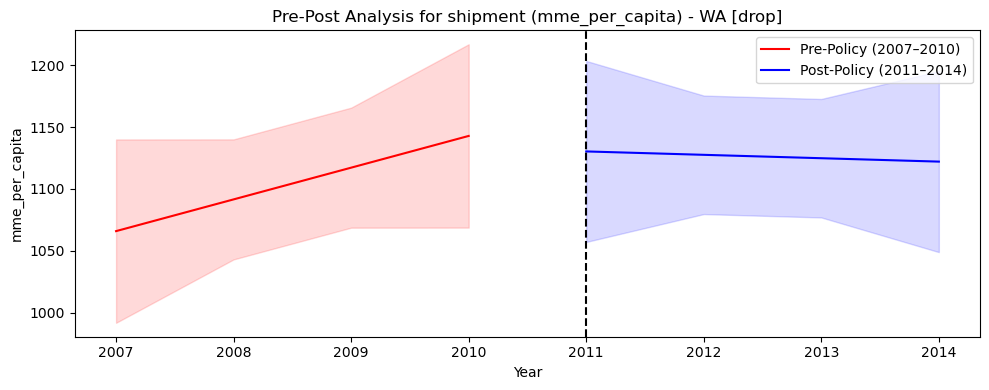

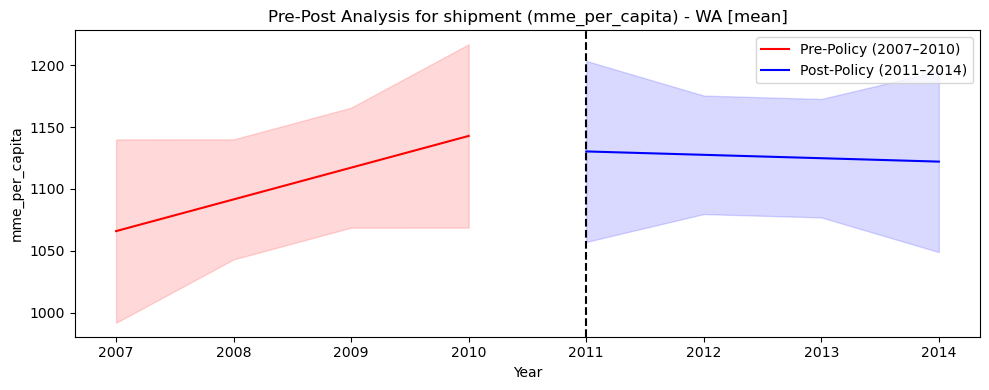

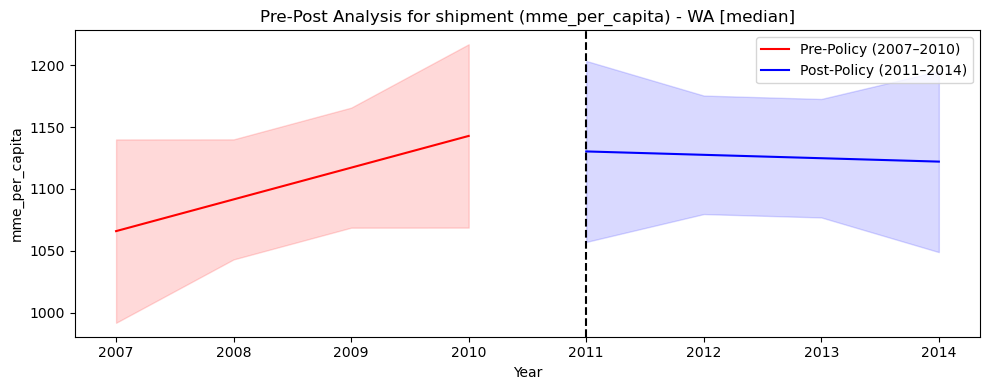

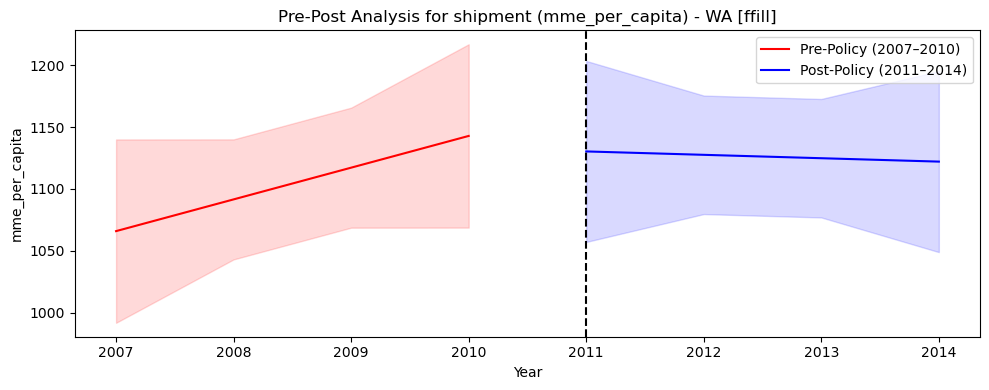

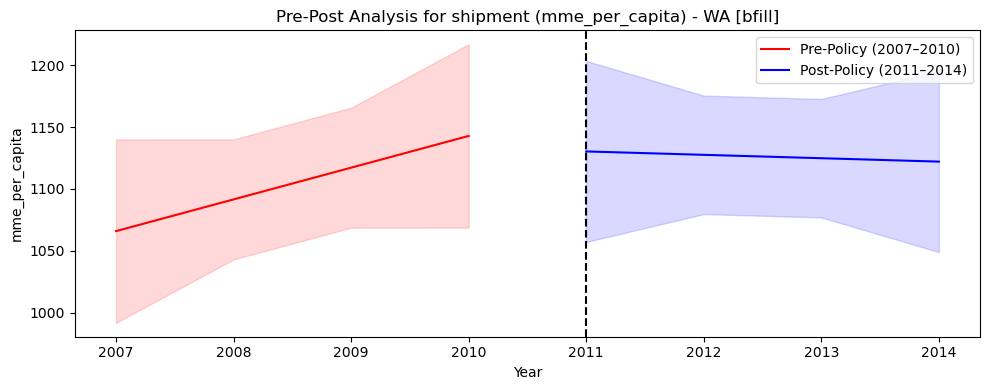

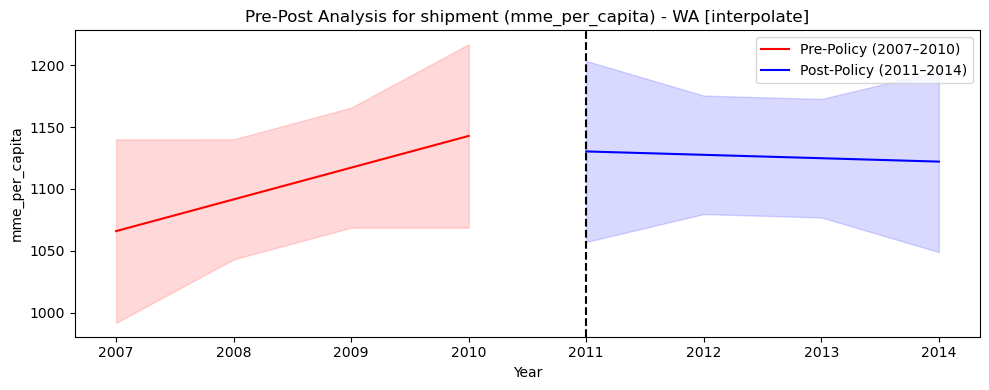

In [42]:
# Washington
# 1. drop
plot_pre_post_shipment(
    df,
    "WA",
    2011,
    rate_col="mme_per_capita",
    nan_strategy="drop",
)

# 2. mean
plot_pre_post_shipment(
    df,
    "WA",
    2011,
    rate_col="mme_per_capita",
    nan_strategy="mean",
)

# 3. median
plot_pre_post_shipment(
    df,
    "WA",
    2011,
    rate_col="mme_per_capita",
    nan_strategy="median",
)

# 4. ffill
plot_pre_post_shipment(
    df,
    "WA",
    2011,
    rate_col="mme_per_capita",
    nan_strategy="ffill",
)

# 5. bfill
plot_pre_post_shipment(
    df,
    "WA",
    2011,
    rate_col="mme_per_capita",
    nan_strategy="bfill",
)

# 6. interpolate
plot_pre_post_shipment(
    df,
    "WA",
    2011,
    rate_col="mme_per_capita",
    nan_strategy="interpolate",
)

## 3. Compare different NaN value dealing ways (smaller plots)

In [43]:
import matplotlib.pyplot as plt
import statsmodels.api as sm


def plot_pre_post_shipment_grid(
    df,
    state_code,
    policy_year,
    rate_col="mme_per_capita",
    pre_window=4,
    post_window=3,
):
    """
    Draw 6 pre-post shipment plots (one for each NaN strategy) in a 3x2 grid.
    NaN handling rules:

      - "drop":        leave NaN unchanged (removed after aggregation)
      - "mean":        fill NaN using state-level mean
      - "median":      fill NaN using state-level median
      - "ffill":       forward-fill within each time series
                       (state+county if county exists, else state only)
      - "bfill":       backward-fill within each time series
                       (state+county if county exists, else state only)
      - "interpolate": linear interpolation within each time series
                       (state+county if county exists, else state only)
    """

    df = df.copy()
    df["state"] = df["state"].str.upper()
    state_code = state_code.upper()

    data_all = df[df["state"] == state_code].copy()
    if data_all.empty:
        print(f"No data for state {state_code}.")
        return

    # Detect county column for granular panel filling
    county_col = "county" if "county" in data_all.columns else None

    fig, axes = plt.subplots(3, 2, figsize=(14, 12))
    axes = axes.flatten()

    # Helper to fit linear trend with CI
    def fit_with_ci(seg):
        X = sm.add_constant(seg["year"])
        model = sm.OLS(seg["rate"], X).fit()
        pred = model.get_prediction(X)
        mean = pred.predicted_mean
        ci = pred.conf_int()
        return mean, ci[:, 0], ci[:, 1]

    strategies = ["drop", "mean", "median", "ffill", "bfill", "interpolate"]

    for i, strat in enumerate(strategies):
        ax = axes[i]
        panel = data_all.copy()

        # -----------------------------------------
        # NaN HANDLING (Unified logic)
        # -----------------------------------------
        if strat != "drop":

            # Mean / median → state level
            if strat in ["mean", "median"]:
                state_g = panel.groupby("state")[rate_col]

                if strat == "mean":
                    panel[rate_col] = state_g.transform(lambda s: s.fillna(s.mean()))
                else:
                    panel[rate_col] = state_g.transform(lambda s: s.fillna(s.median()))

            else:
                # Time-series filling: ffill/bfill/interpolate
                # Group by state+county if available
                if county_col:
                    panel = panel.sort_values(["state", county_col, "year"])
                    group_cols = ["state", county_col]
                else:
                    panel = panel.sort_values(["state", "year"])
                    group_cols = ["state"]

                g = panel.groupby(group_cols)[rate_col]

                if strat == "ffill":
                    panel[rate_col] = g.transform(lambda s: s.ffill())
                elif strat == "bfill":
                    panel[rate_col] = g.transform(lambda s: s.bfill())
                elif strat == "interpolate":
                    panel[rate_col] = g.transform(
                        lambda s: s.interpolate(method="linear")
                    )

        # -----------------------------------------
        # Aggregate to state-year
        # -----------------------------------------
        yearly = (
            panel.groupby("year", as_index=False)[rate_col]
            .mean()
            .rename(columns={rate_col: "rate"})
            .dropna(subset=["rate"])
        )

        if yearly.empty:
            ax.set_title(f"{strat} (no usable data)")
            ax.axis("off")
            continue

        # -----------------------------------------
        # Pre/Post windows
        # -----------------------------------------
        pre = yearly[
            (yearly["year"] >= policy_year - pre_window)
            & (yearly["year"] < policy_year)
        ]
        post = yearly[
            (yearly["year"] >= policy_year)
            & (yearly["year"] <= policy_year + post_window)
        ]

        if pre.empty or post.empty:
            ax.set_title(f"{strat} (not enough data)")
            ax.text(
                0.5,
                0.5,
                "Not enough data",
                ha="center",
                va="center",
                transform=ax.transAxes,
                fontsize=10,
            )
            ax.axis("off")
            continue

        # -----------------------------------------
        # Regression + CI
        # -----------------------------------------
        pre_mean, pre_low, pre_high = fit_with_ci(pre)
        post_mean, post_low, post_high = fit_with_ci(post)

        # -----------------------------------------
        # Plot
        # -----------------------------------------
        ax.plot(pre["year"], pre_mean, color="red", label="Pre")
        ax.fill_between(pre["year"], pre_low, pre_high, color="red", alpha=0.15)

        ax.plot(post["year"], post_mean, color="blue", label="Post")
        ax.fill_between(post["year"], post_low, post_high, color="blue", alpha=0.15)

        ax.axvline(policy_year, color="black", linestyle="--")

        ax.set_title(strat, fontsize=11)
        ax.set_xlabel("Year")
        ax.set_ylabel(rate_col)

    # Turn off unused axes
    for j in range(len(strategies), len(axes)):
        axes[j].axis("off")

    fig.suptitle(
        f"{state_code} shipment pre-post ({rate_col}) — 6 NaN strategies", fontsize=16
    )
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

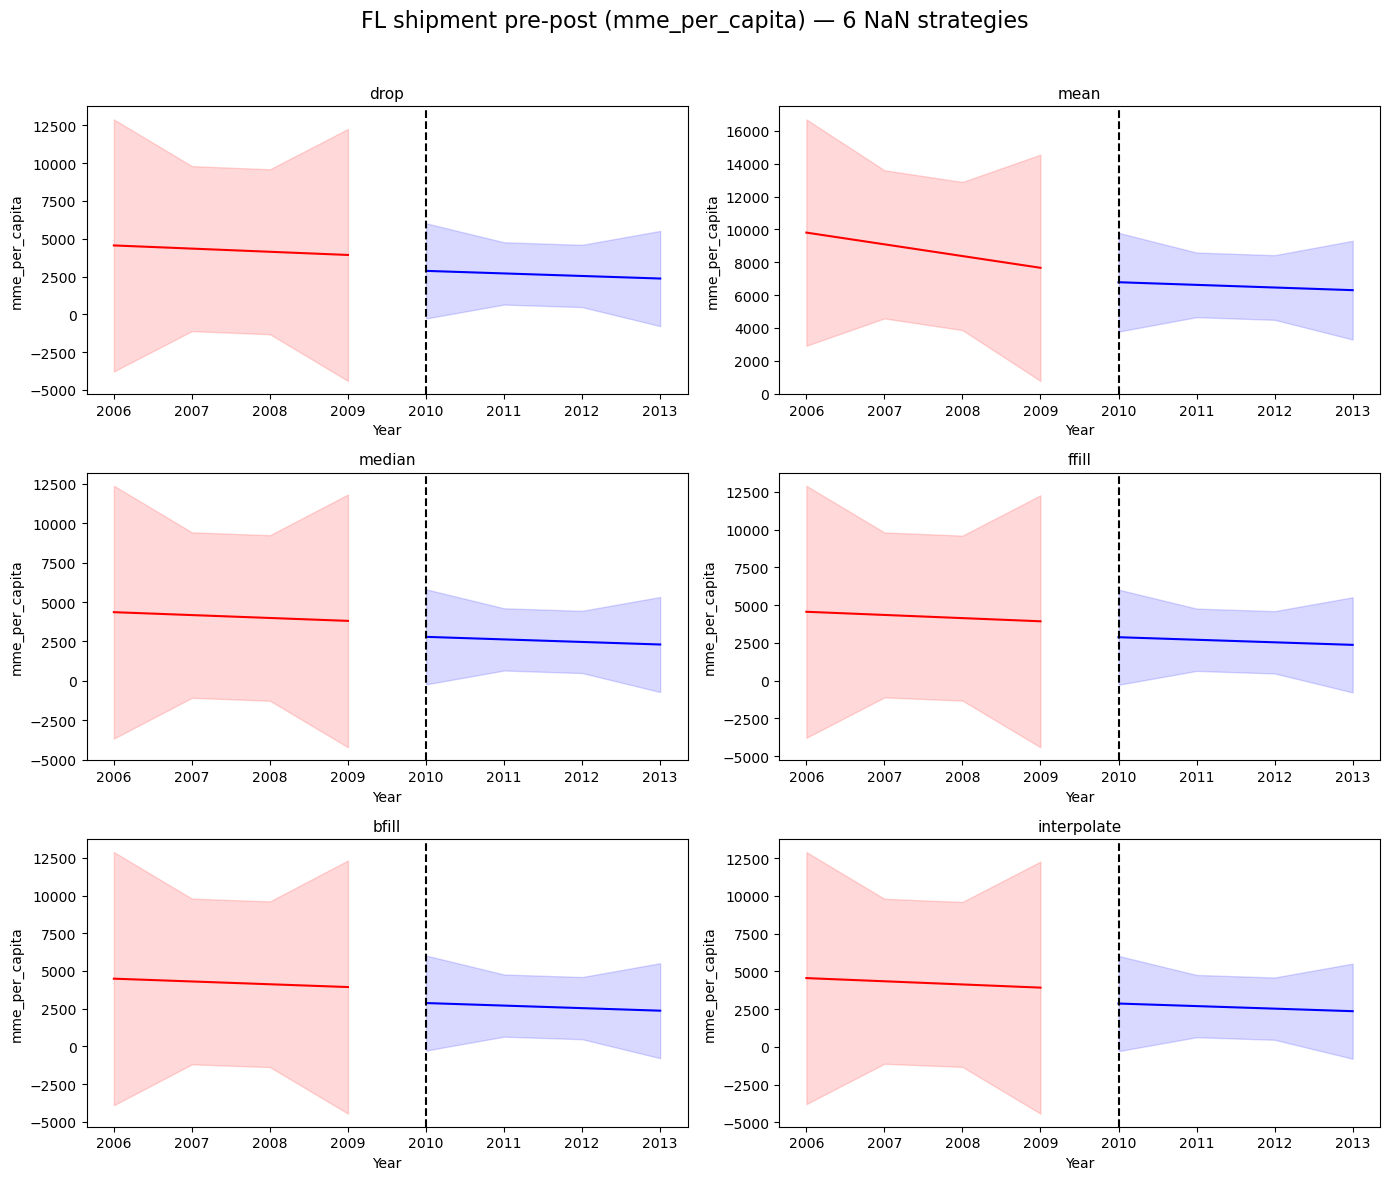

In [44]:
# Florida
plot_pre_post_shipment_grid(
    df,
    state_code="FL",
    policy_year=2010,
    rate_col="mme_per_capita",
    pre_window=4,
    post_window=3,
)

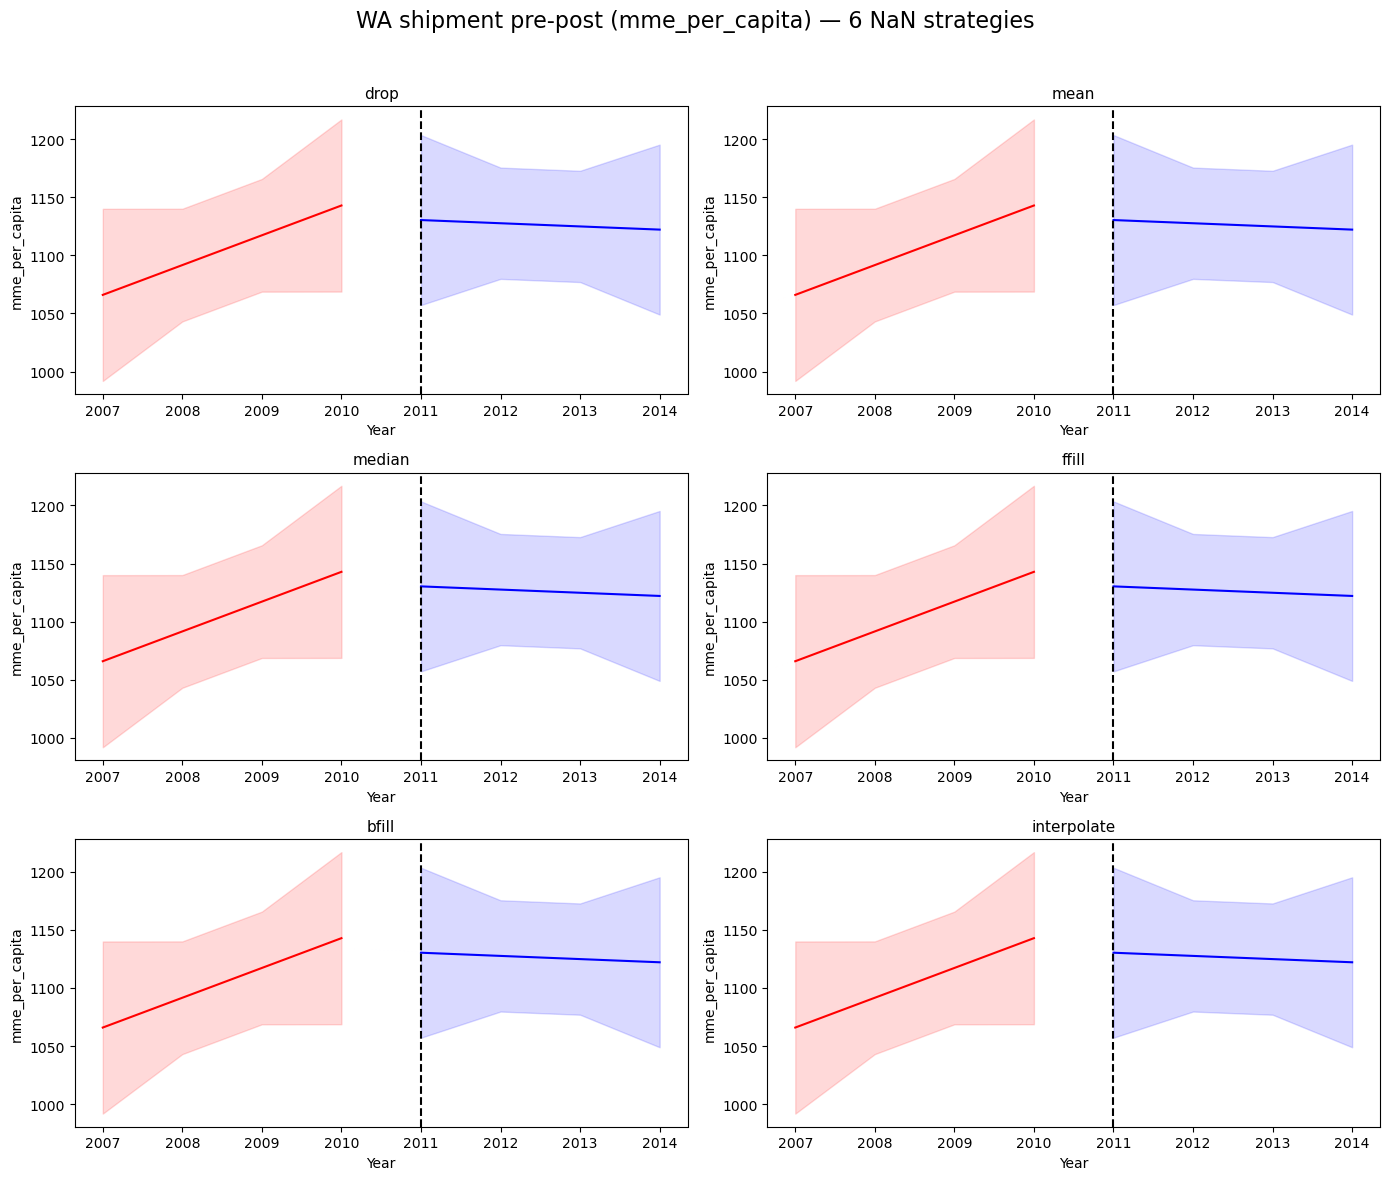

In [45]:
# Washington
plot_pre_post_shipment_grid(
    df,
    state_code="WA",
    policy_year=2011,
    rate_col="mme_per_capita",
    pre_window=4,
    post_window=3,
)

## 4. Final Result (for Shipment) (Pending now)